# EDA Univariate Analysis: Amazon UK Product Insights

**Objective**: Explore product listing dynamics on Amazon UK — category distribution, pricing, and ratings — to surface business-relevant patterns.

**Dataset**: [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [4]:
df = pd.read_csv('dataset/amz_uk_price_prediction_dataset.csv')
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df.shape
df.info()
df.describe(include='all')

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
count,2.443651e+06,2443651,2443651,2.443651e+06,2.443651e+06,2.443651e+06,2443651,2.443651e+06,2443651
unique,NaN,2222742,2077591,NaN,NaN,NaN,2,NaN,296
top,NaN,B0884G1PZ5,OYhmc Portable Pedal Exerc,NaN,NaN,NaN,False,NaN,Sports & Outdoors
freq,NaN,7,723,NaN,NaN,NaN,2435671,NaN,836265
mean,1.370545e+06,NaN,NaN,2.152836e+00,4.806278e+02,8.924381e+01,NaN,2.589699e+01,NaN
std,8.160562e+05,NaN,NaN,2.194865e+00,5.944124e+03,3.456089e+02,NaN,2.404837e+02,NaN
min,1.000000e+00,NaN,NaN,0.000000e+00,0.000000e+00,0.000000e+00,NaN,0.000000e+00,NaN
25%,6.589215e+05,NaN,NaN,0.000000e+00,0.000000e+00,9.990000e+00,NaN,0.000000e+00,NaN
50%,1.349029e+06,NaN,NaN,0.000000e+00,0.000000e+00,1.909000e+01,NaN,0.000000e+00,NaN
75%,2.060686e+06,NaN,NaN,4.400000e+00,5.900000e+01,4.599000e+01,NaN,0.000000e+00,NaN


## Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

In [36]:
category_counts = df['category'].value_counts()
category_counts.head(5)


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

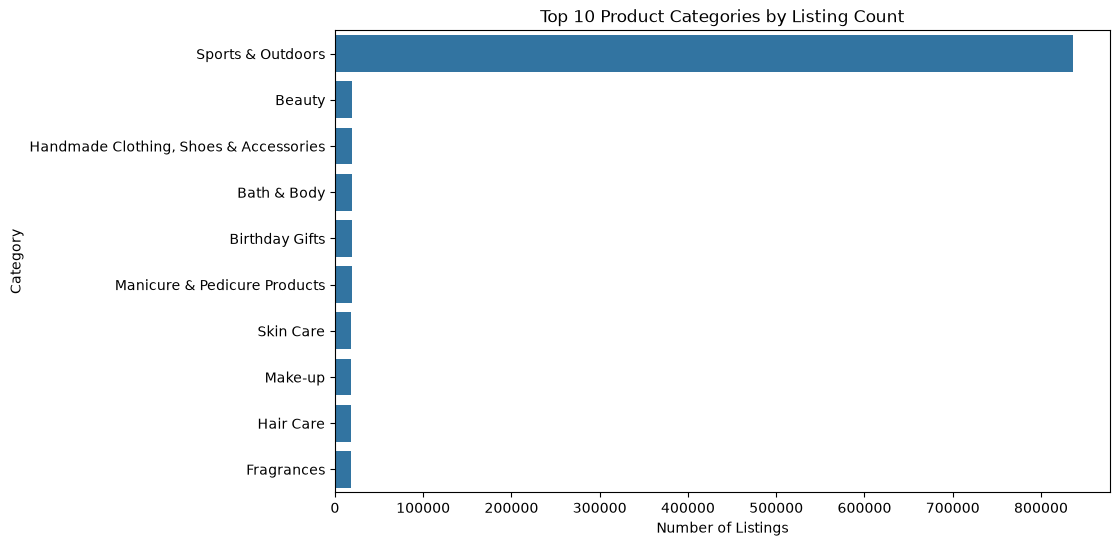

In [19]:
top_n = category_counts.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_n.values, y=top_n.index)
plt.xlabel('Number of Listings')
plt.ylabel('Category')
plt.title('Top 10 Product Categories by Listing Count')
plt.show()

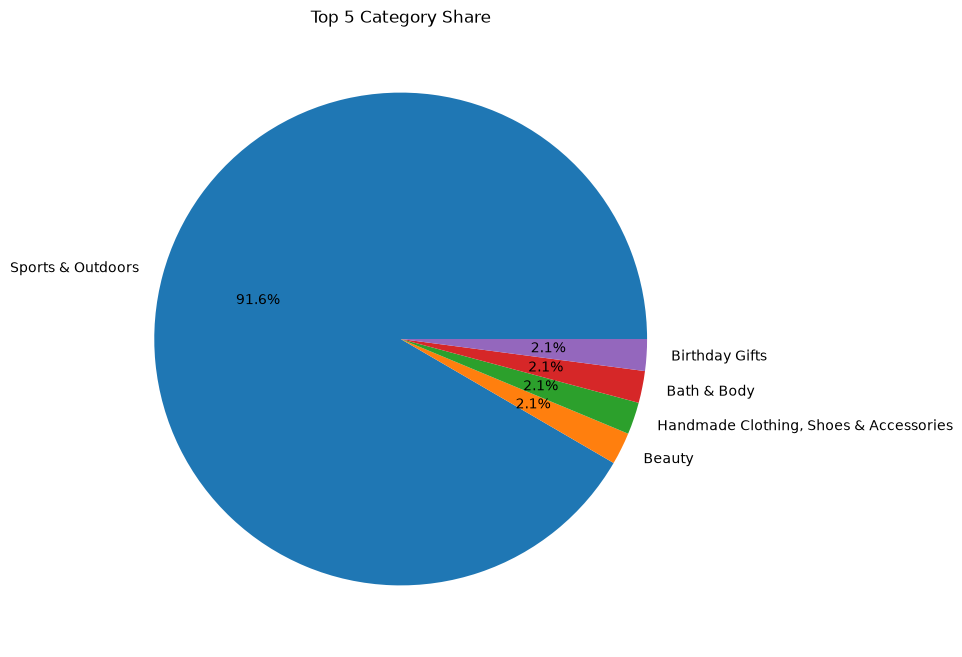

In [20]:
top_5 = category_counts.head(5)

plt.figure(figsize=(8, 8))
plt.pie(top_5.values, labels=top_5.index, autopct='%1.1f%%')
plt.title('Top 5 Category Share')
plt.show()

## Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

In [37]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

mean_price, median_price, mode_price

(np.float64(89.24380943923661), np.float64(19.09), np.float64(9.99))

The average price is £89.24, but the mode is only £9.99, and the median sits at £19.09, much closer to the mode than to the mean. That large gap between mean and median/mode is a sign of right skew: most products are cheap, but a smaller number of very expensive products are pulling the mean far above where most of the data actually sits.

In [38]:
variance = df['price'].var()
std_dev = df['price'].std()
price_range = df['price'].max() - df['price'].min()
iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)

variance, std_dev, price_range, iqr

(np.float64(119445.48532254901),
 np.float64(345.60886175349873),
 np.float64(100000.0),
 np.float64(36.0))

The range is £100,000, but the IQR is only £36. That massive gap between range and IQR is itself the "significant spread" indicator: it means a tiny number of extreme outliers (very expensive products) are stretching the range enormously, while the bulk of ordinary listings are actually clustered in a fairly narrow, affordable band. The standard deviation (£345.61) being nearly 10x the IQR reinforces this — std is sensitive to those same outliers, IQR isn't.

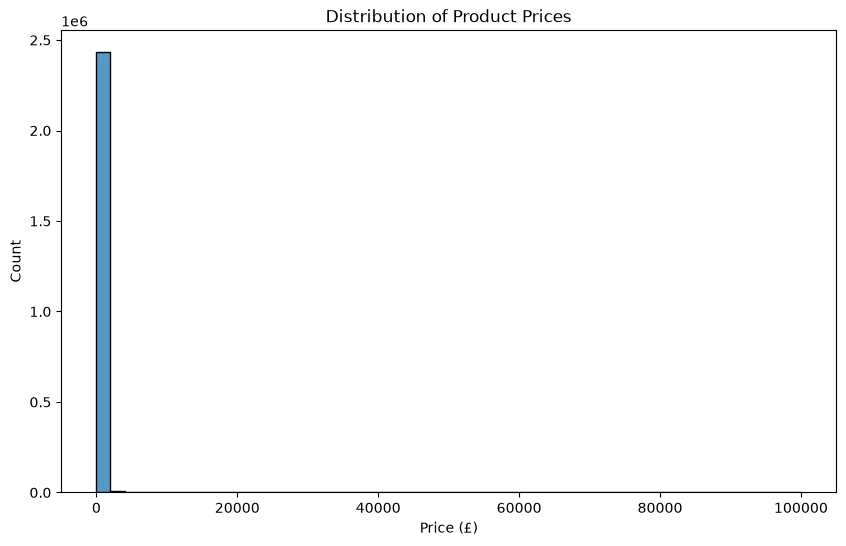

In [39]:
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], bins=50)
plt.xlabel('Price (£)')
plt.title('Distribution of Product Prices')
plt.show()

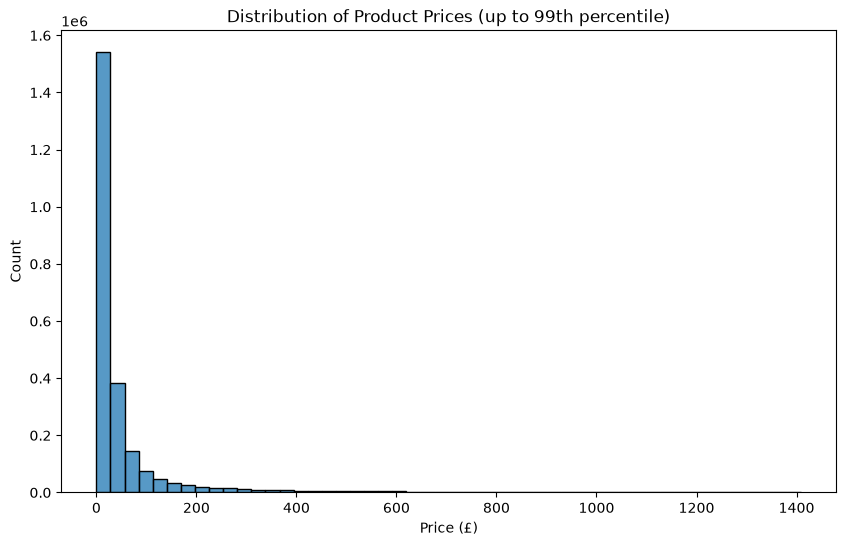

In [46]:
price_99 = df['price'].quantile(0.99)

plt.figure(figsize=(10, 6))
sns.histplot(df[df['price'] <= price_99]['price'], bins=50)
plt.xlabel('Price (£)')
plt.title('Distribution of Product Prices (up to 99th percentile)')
plt.show()

The unfiltered histogram is unreadable because a small number of extreme-priced outliers force matplotlib to scale the x-axis out to £100,000, compressing the vast majority of normally-priced products into a single bar near zero. Filtering to the 99th percentile removes the extreme tail and reveals the actual shape of the distribution for typical products.

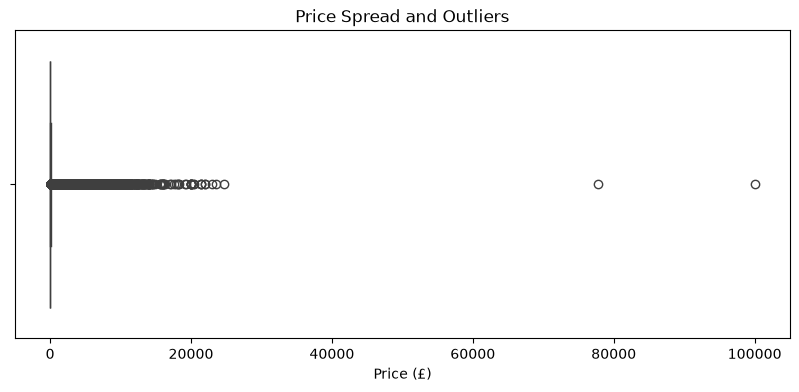

In [40]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['price'])
plt.xlabel('Price (£)')
plt.title('Price Spread and Outliers')
plt.show()

Yes, there are clearly products priced far above the rest — the box itself (middle 50% of prices) is compressed near £0–36, while individual outlier points extend out toward £100,000, confirming the right-skew pattern already suggested by the mean/median/mode gap.

In [41]:
## Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

Object `ratings` not found.


In [42]:
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]

mean_rating, median_rating, mode_rating

(np.float64(2.152836472966066), np.float64(0.0), np.float64(0.0))

Most listed products have never been rated, and among those that have, ratings skew high.

In [43]:
rating_var = df['stars'].var()
rating_std = df['stars'].std()
rating_iqr = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

rating_var, rating_std, rating_iqr

(np.float64(4.817434029796864), np.float64(2.194865378513421), np.float64(4.4))

An IQR of 4.4 on a 0–5 scale spans almost the entire possible range — that looks like massive inconsistency. But as flagged in 1b, this isn't really "customers disagree wildly." It's the zero-inflation effect: the 25th percentile sits at 0 (unrated) while the 75th percentile sits near 4.4 (typical of rated products), so the IQR is measuring the gap between "unrated" and "rated-and-liked," not genuine disagreement among customers who did rate. This is a good example of why you shouldn't report dispersion statistics without inspecting the shape of the distribution first — the number is technically correct but the framing ("wide variation in feedback") would be misleading without this context.

In [44]:
rating_skew = df['stars'].skew()
rating_kurt = df['stars'].kurt()

rating_skew, rating_kurt

(np.float64(0.08120735761080881), np.float64(-1.9260061280432994))

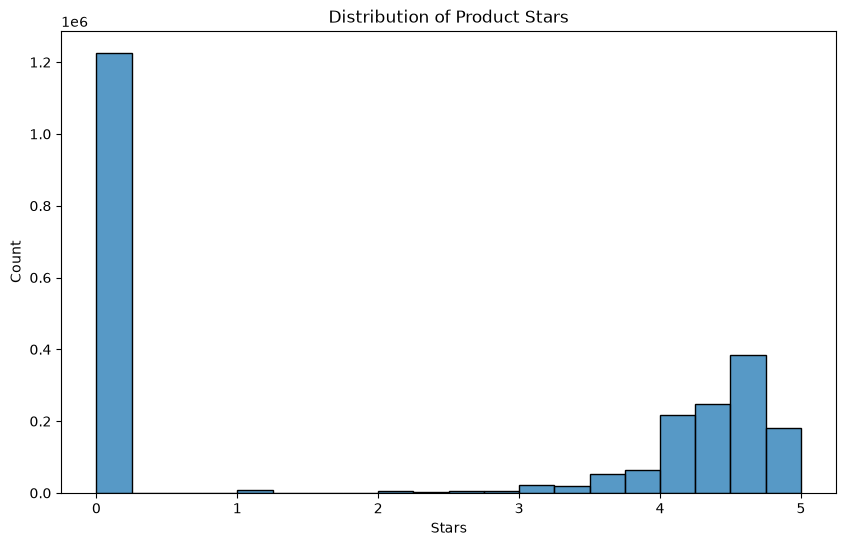

In [45]:
plt.figure(figsize=(10, 6))
sns.histplot(df['stars'], bins=20)
plt.xlabel('Stars')
plt.title('Distribution of Product Stars')
plt.show()